In [1]:
import matplotlib.pyplot as plt
import numpy as np
from IPython.display import clear_output

In [36]:
Nx = 128
x = np.linspace(-15,15,Nx)
dx = x[1] - x[0]

Nt = 5000
T = 30.0
t = np.linspace(0,T,Nt)
dt = t[1] - t[0]

u0 = np.exp(-100*(x-0.5)**2)
v = 2.0
u0 = 0.5 * v *  1 / (np.cosh(np.sqrt(v) * (x + 10) / 2) ** 2) + 0.2 * v *  1 / (np.cosh(np.sqrt(v) * (x - 5) / 2) ** 2)
u0 = np.concatenate([[u0[0], u0[0]], u0, [u0[-1], u0[-1]]])
up = u0.copy()
un = up.copy()

alpha = 6 * dt / (2 * dx)
beta = dt / (2 * dx**3)

U = np.zeros((Nt, Nx))

for k in range(1,Nt):
    un = up.copy()
    for ite in range(10000):
        f = un[2:-2] - up[2:-2] + alpha * (un[3:-1]**2 - un[1:-3]**2) / 2 + beta * (un[4:] - 2 * un[3:-1] + 2 * un[1:-3] - un[:-4])
        J = np.diag(np.ones_like(un[2:-2]), k=0) + np.diag(alpha * un[3:-2] - 2 * beta, k=1) + np.diag(-alpha * un[2:-3] + 2 * beta, k=-1) + np.diag(beta * np.ones_like(un[3:-3]), k=2) + np.diag(-beta * np.ones_like(un[3:-3]), k=-2)
        du = np.linalg.solve(J, -f)
        un[2:-2] += du

        if np.linalg.norm(du) < 1e-9 : break

    un[0], un[1] = un[-4], un[-3]
    un[-1], un[-2] = un[3], un[2]

    up = un.copy()

    U[k] = un[2:-2]

#f = un[i] - up[i] + alpha * (un[i + 1]**2 - un[i - 1]**2) / 2 + beta * (un[i + 2] - 2 * un[i + 1] + 2 * un[i - 1] - un[i - 2]) = 0
#df/dun[i] = 1
#df/dun[i+1] = alpha * un[i+1] - 2 * beta
#df/dun[i-1] = -alpha * un[i-1] + 2 * beta
#df/dun[i+2] = beta
#df/dun[i-2] = -beta

    if k % 100000 == 0:
        clear_output(wait=True)
        plt.plot(x, un[2:-2])
        plt.ylim(-0.1,2.25)
        plt.title(f"Time : {k * dt:.2f} sec")
        plt.show()
        plt.pause(0.01)

Text(0, 0.5, 'Time (s)')

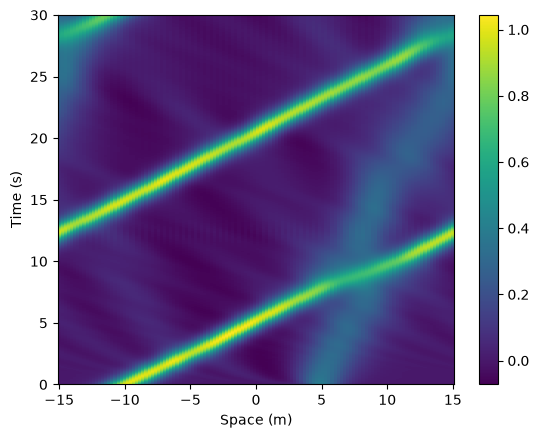

In [37]:
plt.pcolormesh(x, t, U)
plt.colorbar()
plt.xlabel("Space (m)")
plt.ylabel("Time (s)")